# Assignment 4 — One- and Two-Sample Tests

**Course:** STA1

**Group members:** Bibek Paudel, Dora Buruncuk, Supendra Bogati

## Table of contents
1. [Part 1 — One-sample decisions](#part1)
2. [Part 2 — Independent coating processes](#part2)
3. [Part 3 — Paired building-energy measurements](#part3)
4. [Part 4 — Comparing two independent proportions](#part4)
5. [Part 5 — AI-use and conclusion](#part5)

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import (t, norm, binom, binomtest, ttest_1samp, ttest_ind, ttest_rel,
                         shapiro, probplot, skew)
from statsmodels.stats.proportion import proportion_confint

DATA = "data/"

sensor = pd.read_csv(DATA + "assignment03_sensor_calibration.csv")    # Part 1
access = pd.read_csv(DATA + "assignment03_access_control.csv")        # Part 1
coating = pd.read_csv(DATA + "assignment04_coating_durability.csv")   # Part 2
energy = pd.read_csv(DATA + "assignment04_energy_retrofit.csv")       # Part 3

print(f"sensor: {sensor.shape[0]} rows x {sensor.shape[1]} columns")
print(f"access: {access.shape[0]} rows x {access.shape[1]} columns")
print(f"coating: {coating.shape[0]} rows x {coating.shape[1]} columns")
print(f"energy: {energy.shape[0]} rows x {energy.shape[1]} columns")

sensor: 64 rows x 2 columns
access: 240 rows x 2 columns
coating: 92 rows x 3 columns
energy: 36 rows x 3 columns


<a id="part1"></a>
# Part 1 — One-sample decisions

## Mean sensor error

> Use assignment03_sensor_calibration.csv. The engineering team asks whether population mean
> calibration error differs from zero; errors with absolute mean below $0.50\ ^\circ\mathrm C$ are
> regarded as small in practice.

**Population:** all temperature sensors of this type.

**Parameter:** $\mu$, the population mean calibration error in °C, where error = sensor reading −
reference temperature.

**Observational unit:** one sensor.

**Design:** one sample of 64 independently selected sensors. $\mu$ is compared with the fixed value
0 °C, so the effect is $\bar x - 0$.

**Assumptions:** independent errors from one population, and errors close to normal (or $n$ large
enough for $\bar X$ to be close to normal).

n = 64, mean = 0.1883 °C, s = 0.6257 °C, SE = 0.0782 °C


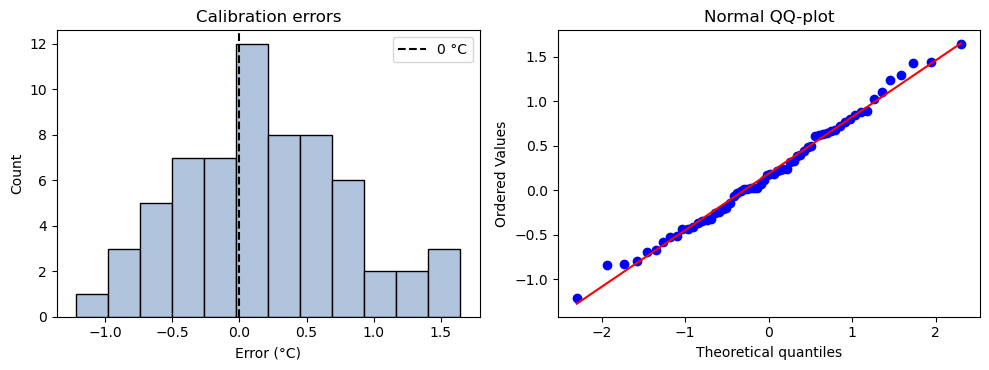

Shapiro–Wilk W = 0.990, p = 0.874


In [2]:
errors = sensor["calibration_error_c"].to_numpy()

n = errors.size
xbar = errors.mean()
s = errors.std(ddof=1)
se = s / np.sqrt(n)
print(f"n = {n}, mean = {xbar:.4f} °C, s = {s:.4f} °C, SE = {se:.4f} °C")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(errors, bins=12, color="lightsteelblue", edgecolor="black")
axes[0].axvline(0, color="black", ls="--", label="0 °C")
axes[0].set(title="Calibration errors", xlabel="Error (°C)", ylabel="Count")
axes[0].legend()
probplot(errors, dist="norm", plot=axes[1])
axes[1].set_title("Normal QQ-plot")
fig.tight_layout()
plt.show()

W, p_sw = shapiro(errors)
print(f"Shapiro–Wilk W = {W:.3f}, p = {p_sw:.3f}")

**Assumption check:** the histogram is roughly symmetric, the QQ points follow the line, and
Shapiro–Wilk ($p = 0.874$) gives no evidence against normality, so the $t$ procedure is reasonable.
These checks cannot show independence; that depends on how the sensors were selected.

### a)

> State $H_0$, the two-sided $H_1$, and $\alpha=0.05$. Use a one-sample $t$ procedure and report the
> sample mean, test statistic, degrees of freedom, and two-sided $p$-value.

$$H_0: \mu = 0\ ^\circ\mathrm C \qquad H_1: \mu \ne 0\ ^\circ\mathrm C \qquad \alpha = 0.05$$

$$t = \frac{\bar x - 0}{s/\sqrt n}, \qquad \text{df} = n - 1$$

In [3]:
mu0 = 0.0
alpha = 0.05

t_obs = (xbar - mu0) / se
df = n - 1
p_two = 2 * t.sf(abs(t_obs), df)
res = ttest_1samp(errors, popmean=mu0, alternative="two-sided")   # check with SciPy

print(f"sample mean = {xbar:.4f} °C")
print(f"t = ({xbar:.5f} - 0) / {se:.5f} = {t_obs:.4f}")
print(f"df = {df}")
print(f"two-sided p = {p_two:.4f}")
print(f"SciPy check: t = {res.statistic:.4f}, df = {res.df}, p = {res.pvalue:.4f}")
print(f"decision at alpha = {alpha}:", "reject H0" if p_two < alpha else "fail to reject H0")

sample mean = 0.1883 °C
t = (0.18827 - 0) / 0.07822 = 2.4069
df = 63
two-sided p = 0.0190
SciPy check: t = 2.4069, df = 63, p = 0.0190
decision at alpha = 0.05: reject H0


### b)

> Interpret the $p$-value as a tail probability conditional on $H_0$ and the assumptions. State the
> decision and a contextual conclusion without treating the $p$-value as $P(H_0\mid\text{data})$.

**$p$-value:** if $\mu = 0$ and the assumptions hold, a $t$ statistic at least as far from 0 as
2.41, in either direction, would occur with probability 0.019. It is not the probability that $H_0$
is true.

**Decision:** $p = 0.019 < 0.05$, so we reject $H_0$.

**Conclusion:** the data give evidence that the population mean calibration error differs from
0 °C. The sample mean of 0.19 °C suggests the sensors read slightly high on average.

### c)

> Reuse or reconstruct the 95% $t$ interval and explain its duality with this two-sided test. Compare
> it with the practical limits and distinguish statistical significance from practical importance.

$$\bar x \pm t_{n-1,\,0.975}\,\frac{s}{\sqrt n}$$

In [4]:
ci_lo, ci_hi = t.interval(0.95, df, loc=xbar, scale=se)

print(f"95% t interval for mu = [{ci_lo:.4f}, {ci_hi:.4f}] °C")
print("0 °C inside the interval:", ci_lo <= 0 <= ci_hi)
print("interval inside the practical limits of ±0.50 °C:", -0.50 < ci_lo and ci_hi < 0.50)

95% t interval for mu = [0.0320, 0.3446] °C
0 °C inside the interval: False
interval inside the practical limits of ±0.50 °C: True


**Duality:** the interval and the two-sided test use the same $t$ distribution, SE and df. A value
$\mu_0$ is rejected at $\alpha = 0.05$ exactly when it lies outside the 95 % interval. 0 °C lies
outside $[0.0320,\ 0.3446]$ °C, which matches the rejection in a).

**Practical importance:** the whole interval lies inside $\pm 0.50$ °C, so even the largest
plausible mean error, 0.34 °C, is small in practice. The result is statistically significant but not
practically important: the sensors read slightly high on average, but by too little to matter.

**Limitation:** the result applies only to sensors like these 64. The errors are measured against
the reference temperature, so a bias in the reference would look like a sensor error.

## False-rejection probability

> Use assignment03_access_control.csv. The pre-specified question is whether the false-rejection
> probability exceeds the 5% target.

**Population:** all legitimate login attempts under the test conditions.

**Parameter:** $p$, the probability that a legitimate attempt is falsely rejected.

**Observational unit:** one login attempt.

**Design:** 240 independently staged attempts. If the attempts are independent with the same $p$,
the number of false rejections is $X \sim \text{Bin}(240, p)$. $p$ is compared with the fixed
target 0.05.

### a)

> State the one-sided hypotheses. Perform an exact binomial test and report $\hat p$, the $p$-value,
> decision, and conclusion.

$$H_0: p \le 0.05 \qquad H_1: p > 0.05 \qquad \alpha = 0.05$$

The exact $p$-value is the upper tail of the binomial distribution at the null value $p_0 = 0.05$:

$$p\text{-value} = P(X \ge x \mid p = 0.05)$$

In [5]:
y = access["false_reject"]

n = len(y)
x = int(y.sum())
p_hat = x / n
res_b = binomtest(x, n=n, p=0.05, alternative="greater")

print(f"n = {n}, x = {x}, p_hat = {p_hat:.4f}")
print(f"expected false rejections if p = 0.05: {n * 0.05:.0f}")
print(f"exact one-sided p = P(X >= {x} | p = 0.05) = {res_b.pvalue:.4f}")
print(f"check with binom.sf: {binom.sf(x - 1, n, 0.05):.4f}")   # sf(x - 1) = P(X >= x)
print(f"decision at alpha = {alpha}:", "reject H0" if res_b.pvalue < alpha else "fail to reject H0")

n = 240, x = 20, p_hat = 0.0833
expected false rejections if p = 0.05: 12
exact one-sided p = P(X >= 20 | p = 0.05) = 0.0185
check with binom.sf: 0.0185
decision at alpha = 0.05: reject H0


**Decision:** $p = 0.0185 < 0.05$, so we reject $H_0$.

**Conclusion:** that is 20 false rejections in 240 attempts ($\hat p = 0.0833$), more than the 12
expected at the 5 % target. The data give evidence that the false-rejection probability under the
test conditions exceeds 5 %.

**Limitation:** the attempts were staged under test conditions, so the false-rejection rate for real
users may differ.

### b)

> Use the Wilson interval as an estimate of plausible values, while explaining why a two-sided Wilson
> interval is not the exact dual of a one-sided exact test.

In [6]:
wilson_lo, wilson_hi = proportion_confint(x, n, alpha=0.05, method="wilson")
print(f"95% Wilson interval for p = [{wilson_lo:.4f}, {wilson_hi:.4f}]")

95% Wilson interval for p = [0.0546, 0.1252]


**Plausible values:** false-rejection probabilities from about 5.5 % to 12.5 % are compatible with
the data. The whole interval lies above the 5 % target.

**Why it is not the exact dual:** duality needs a two-sided test and an interval from the same
method at the same level. Here the test is one-sided at 5 % and uses the exact binomial
distribution, while the Wilson interval is two-sided (2.5 % in each tail) and uses the normal
approximation. Here both point the same way, but duality does not guarantee that, so the decision
comes from the exact test and the interval describes how large $p$ may be.

### c)

> Describe Type I and Type II errors in one of the two one-sample studies and state an operational
> consequence of each.

For the false-rejection study ($H_0: p \le 0.05$):

**Type I error (false positive):** concluding that $p$ exceeds 5 % when it does not. Its
probability is at most $\alpha = 0.05$. Consequence: the team spends time retuning, or delays the
release of, a system that already meets the target.

**Type II error (false negative):** failing to conclude that $p$ exceeds 5 % when it does. Its
probability is $\beta$, and the power is $1 - \beta$. Consequence: the system is released and more
legitimate users are locked out than the target allows, causing support calls and lost work.

<a id="part2"></a>
# Part 2 — Independent coating processes

> The file assignment04_coating_durability.csv contains independent specimens from a standard
> and modified coating process. Let
> $$\delta = \mu_{\text{modified}} - \mu_{\text{standard}},$$
> measured in durability hours. An increase of at least 8 hours is considered practically
> important.

**Population:** all coated specimens that could be produced by each process.

**Parameter:** $\delta = \mu_{\text{modified}} - \mu_{\text{standard}}$, the difference in mean
durability in hours. A positive $\delta$ means the modified process lasts longer on average than
the standard process.

**Observational unit:** one coated specimen.

**Design:** two independent groups, standard and modified, since each specimen is coated by only
one process.

**Assumptions:** the specimens are representative of each process, the two groups are independent
of each other and within themselves, and the values in each group are close to normal, or each
$n$ is large enough for the sample mean to be, so that a $t$ procedure is reasonable.

## a)

> Explain why the samples are independent rather than paired. Report group $n$, mean, sample
> standard deviation, and boxplots.

**Why independent, not paired:** Each specimen is coated by exactly one process, standard or
modified, so no specimen in one group has a specific and meaningful partner in the other
(Definition 8.2). Knowing which specimens are in the standard group says nothing about the
values in the modified group, so the two samples are independent (Definition 8.1).

           n    mean      s
standard  44  117.29  15.75
modified  48  132.49  22.19


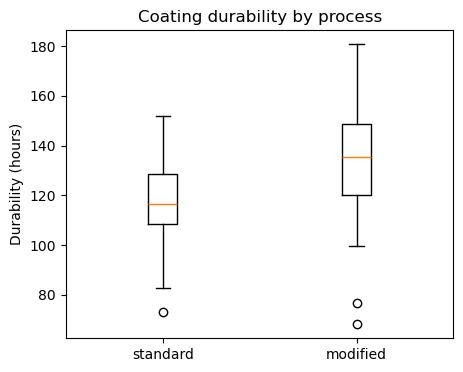

In [7]:
standard = coating.loc[coating["process"] == "standard", "durability_h"].to_numpy()
modified = coating.loc[coating["process"] == "modified", "durability_h"].to_numpy()

n1, n2 = len(standard), len(modified)
x1, x2 = standard.mean(), modified.mean()
s1, s2 = standard.std(ddof=1), modified.std(ddof=1)

summary = pd.DataFrame({"n": [n1, n2], "mean": [x1, x2], "s": [s1, s2]},
                        index=["standard", "modified"])
print(summary.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([standard, modified])
ax.set_xticklabels(["standard", "modified"])
ax.set_ylabel("Durability (hours)")
ax.set_title("Coating durability by process")
plt.show()

**Group summary:** modified specimens lasted longer on average (132.49 vs 117.29 hours) and
showed more spread ($s=22.19$ vs $15.75$ hours). The boxplot shows the modified group's box and
median sitting higher than the standard group's.

## b)

> State two-sided hypotheses about $\delta$. Use Welch's two-sample $t$ procedure and report the
> estimated difference, 95% confidence interval, statistic, approximate degrees of freedom, and
> $p$-value. Do not use a preliminary variance test to switch automatically between pooled and
> Welch procedures.

$$H_0: \delta = 0 \qquad H_1: \delta \ne 0 \qquad \alpha = 0.05$$

The classical pooled test needs equal population variances. Welch's test does not, so there is no
need to test for equal variances first.

Let $1=$ standard and $2=$ modified:

$$\hat\delta = \bar x_2 - \bar x_1, \qquad \text{SE} = \sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}$$

$$t_{\text{obs}} = \frac{\hat\delta - 0}{\text{SE}}, \qquad
\nu = \frac{\left(\frac{s_1^2}{n_1}+\frac{s_2^2}{n_2}\right)^2}
{\frac{(s_1^2/n_1)^2}{n_1-1}+\frac{(s_2^2/n_2)^2}{n_2-1}}
\qquad \text{(Theorem 8.1)}$$

In [8]:
alpha = 0.05

diff = x2 - x1   # modified - standard = delta_hat
se = np.sqrt(s1**2 / n1 + s2**2 / n2)

nu = (s1**2 / n1 + s2**2 / n2)**2 / ((s1**2/n1)**2/(n1-1) + (s2**2/n2)**2/(n2-1))

t_crit = t.ppf(0.975, nu)
moe = t_crit * se
ci_lo, ci_hi = diff - moe, diff + moe

t_obs = diff / se
p_two = 2 * t.sf(abs(t_obs), nu)

res = ttest_ind(modified, standard, equal_var=False)   # check with SciPy

print(f"delta_hat = {x2:.2f} - {x1:.2f} = {diff:.2f} hours")
print(f"SE = {se:.4f}")
print(f"df (Welch) = {nu:.2f}")
print(f"t_0.975 = {t_crit:.4f}")
print(f"95% CI = [{ci_lo:.2f}, {ci_hi:.2f}] hours")
print(f"t = {t_obs:.3f}")
print(f"two-sided p = {p_two:.4f}")
print(f"SciPy check: t = {res.statistic:.3f}, df = {res.df:.2f}, p = {res.pvalue:.4f}")
print(f"decision at alpha = {alpha}:", "reject H0" if p_two < alpha else "fail to reject H0")

delta_hat = 132.49 - 117.29 = 15.20 hours
SE = 3.9867
df (Welch) = 84.84
t_0.975 = 1.9883
95% CI = [7.27, 23.13] hours
t = 3.812
two-sided p = 0.0003
SciPy check: t = 3.812, df = 84.84, p = 0.0003
decision at alpha = 0.05: reject H0


**Result:** modified specimens last an estimated 15.20 hours longer on average than standard
($\hat\delta=15.20$), 95 % CI $[7.27,\ 23.13]$ hours, $t=3.812$ on $\nu=84.84$ df, two-sided
$p=0.0003$.

**Decision:** $p=0.0003<0.05$, so we reject $H_0$.

**Conclusion:** the data give evidence that the modified process has a higher mean durability
than the standard process.

## c)

> Assess independence from the design and distribution shape and unusual observations from group
> plots or residual diagnostics. State what the plots cannot establish.

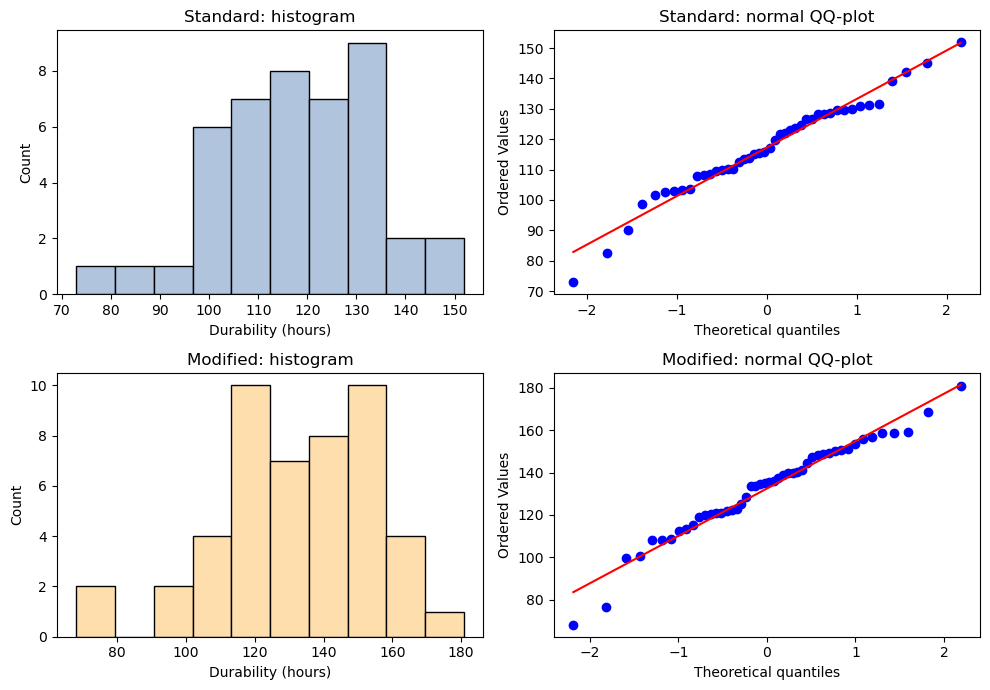

Shapiro–Wilk standard: W = 0.977, p = 0.523
Shapiro–Wilk modified: W = 0.970, p = 0.247
skewness standard: -0.39
skewness modified: -0.59
standard outliers (1.5xIQR rule): [72.93]
modified outliers (1.5xIQR rule): [76.48 68.12]


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0, 0].hist(standard, bins=10, color="lightsteelblue", edgecolor="black")
axes[0, 0].set(title="Standard: histogram", xlabel="Durability (hours)", ylabel="Count")
probplot(standard, dist="norm", plot=axes[0, 1])
axes[0, 1].set_title("Standard: normal QQ-plot")

axes[1, 0].hist(modified, bins=10, color="navajowhite", edgecolor="black")
axes[1, 0].set(title="Modified: histogram", xlabel="Durability (hours)", ylabel="Count")
probplot(modified, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Modified: normal QQ-plot")

fig.tight_layout()
plt.show()

W1, p1 = shapiro(standard)
W2, p2 = shapiro(modified)
print(f"Shapiro–Wilk standard: W = {W1:.3f}, p = {p1:.3f}")
print(f"Shapiro–Wilk modified: W = {W2:.3f}, p = {p2:.3f}")
print(f"skewness standard: {skew(standard):.2f}")
print(f"skewness modified: {skew(modified):.2f}")

def iqr_outliers(x):
    q1, q3 = np.percentile(x, 25), np.percentile(x, 75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return x[(x < lo) | (x > hi)]

print(f"standard outliers (1.5xIQR rule): {iqr_outliers(standard)}")
print(f"modified outliers (1.5xIQR rule): {iqr_outliers(modified)}")

**Independence from the design:** each specimen was coated by only one process, so the two
groups are independent of each other, as in a) (Definition 8.1), not paired (Definition 8.2).
Independence within each group is not shown by this alone: if specimens from the same batch or
test rig share conditions, their durability values could be correlated, and neither the design
nor the plots below can rule that out.

**Distribution shape:** both histograms are roughly symmetric and single-peaked. The QQ-plots
follow the line through most of each sample, but the lowest point in each group falls below it,
and both samples are slightly left-skewed (standard: $-0.39$; modified: $-0.59$). Shapiro–Wilk
gives no evidence against normality for either group (standard: $p=0.523$; modified: $p=0.247$),
so with $n=44$ and $n=48$ the Welch $t$ procedure in b) is still reasonable.

**Unusual observations:** the boxplot in a) flags one low point in the standard group (72.93 h)
and two low points in the modified group (68.12 h and 76.48 h) as 1.5×IQR outliers. None looks
impossible for a durability measurement, and removing them is not justified without independent
evidence of a measurement problem.

**What the plots cannot establish:** histograms, QQ-plots and boxplots describe only the shape of
the values collected. They cannot confirm that the specimens are independent or representative,
since that depends on how they were produced and selected, not on the data's distribution. They
also cannot prove normality, only fail to contradict it, and they say nothing about whether the
coating process itself caused the difference between the groups.

## d)

> Compare the interval with both zero and the 8-hour practical threshold. Give a recommendation
> that reflects statistical uncertainty and practical importance.

In [10]:
print(f"95% CI = [{ci_lo:.2f}, {ci_hi:.2f}] hours")
print("0 inside the interval:", ci_lo <= 0 <= ci_hi)
print("8 inside the interval:", ci_lo <= 8 <= ci_hi)

95% CI = [7.27, 23.13] hours
0 inside the interval: False
8 inside the interval: True


**Versus zero:** the interval $[7.27,\ 23.13]$ hours lies entirely above 0, consistent with
rejecting $H_0$ in b): the data support a real difference between the two processes.

**Versus the 8-hour threshold:** the interval still straddles 8 hours. Values as low as 7.27
hours (below the practical threshold) and as high as 23.13 hours (well above it) are both
compatible with the data.

**Recommendation:** statistical significance and practical importance answer different
questions. The point estimate, 15.20 hours, is almost twice the 8-hour threshold, so the best
guess favours switching to the modified process. But the interval's lower end, 7.27 hours, falls
short of 8 hours, so the data cannot yet rule out an improvement too small to matter. More
specimens would narrow the interval and settle this.

<a id="part3"></a>
# Part 3 — Paired building-energy measurements

> The file assignment04_energy_retrofit.csv records energy use for the same 36 buildings before and
> after a control-system retrofit. Define the paired difference
> $$D = \text{before} - \text{after},$$
> so a positive value represents a reduction.

**Population:** all buildings of this kind that could receive the control-system retrofit.

**Parameter:** $\mu_D$, the population mean reduction in daily energy use in kWh/day, where
$D = \text{before} - \text{after}$. A positive $\mu_D$ means energy use goes down.

**Observational unit:** one building, measured before and after the retrofit.

**Design:** paired, 36 buildings each measured twice. The comparison order before $-$ after is fixed
before the analysis, and the pairs are analysed as one sample of 36 differences.

**Assumptions:** buildings independent of each other and representative, and differences close to
normal (or $n$ large enough for $\bar D$ to be close to normal).

## a)

> Explain the observational unit and why the rows form genuine pairs. Create the difference column
> and report its mean, standard deviation, and standard error.

**Why genuine pairs:** both values in a row come from the same building, so they share its size,
use and occupants (Definition 8.2). The two values in a row are dependent; different buildings are
independent. The analysis uses $n = 36$ pairs, not 72 observations (Section 8.3).

$$D_i = \text{before}_i - \text{after}_i, \qquad \widehat{\text{SE}}(\bar D) = \frac{s_D}{\sqrt n}$$

In [11]:
energy["diff_kwh_day"] = energy["before_kwh_day"] - energy["after_kwh_day"]   # positive = reduction
before = energy["before_kwh_day"].to_numpy()
after = energy["after_kwh_day"].to_numpy()
d = energy["diff_kwh_day"].to_numpy()

n = d.size
d_bar = d.mean()
s_d = d.std(ddof=1)     # SD of the differences
se_d = s_d / np.sqrt(n)  # estimated standard error of the mean difference

print(energy.head().round(2))
print()
print("unique building IDs:", energy["building_id"].is_unique)   # data audit
print("missing values:", int(energy.isna().sum().sum()))
print()
print(f"n    = {n} buildings")
print(f"dbar = {d_bar:.4f} kWh/day")
print(f"s_D  = {s_d:.4f} kWh/day")
print(f"SE   = s_D / sqrt(n) = {s_d:.4f} / {np.sqrt(n):.0f} = {se_d:.4f} kWh/day")
print(f"buildings with higher use after the retrofit (d < 0): {np.sum(d < 0)} of {n}")

   building_id  before_kwh_day  after_kwh_day  diff_kwh_day
0            1           91.57          87.75          3.82
1            2           95.33          90.14          5.19
2            3           85.20          85.61         -0.41
3            4           75.96          64.30         11.66
4            5           85.33          81.90          3.43

unique building IDs: True
missing values: 0

n    = 36 buildings
dbar = 4.8228 kWh/day
s_D  = 4.5036 kWh/day
SE   = s_D / sqrt(n) = 4.5036 / 6 = 0.7506 kWh/day
buildings with higher use after the retrofit (d < 0): 6 of 36


**Audit:** each building appears once, no values are missing, and both columns are daily energy use
in kWh/day for the same building, so all 36 pairs are complete and comparable.

**Summary:** the mean reduction is $\bar d = 4.82$ kWh/day, with $s_D = 4.50$ kWh/day and
SE $= 0.75$ kWh/day. 30 of the 36 buildings used less energy after the retrofit.

## b)

> Plot the paired values and the distribution or QQ-plot of differences. Diagnose the
> differences—not the two raw columns separately—for the paired $t$ procedure.

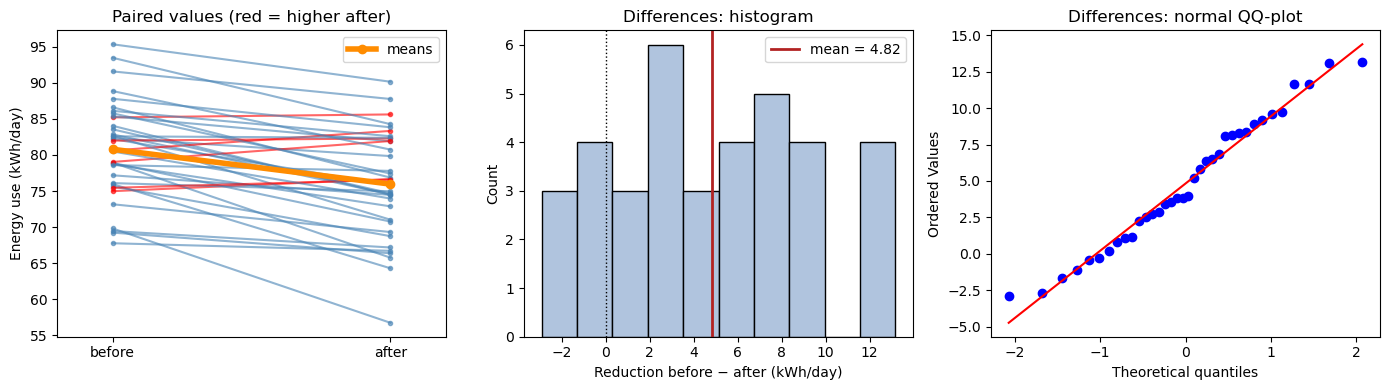

Shapiro–Wilk on the differences: W = 0.969, p = 0.403
skewness of the differences: 0.11
outliers among the differences (1.5xIQR rule): []


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for b, a in zip(before, after):   # one line per building
    axes[0].plot([0, 1], [b, a], color="red" if a > b else "steelblue", alpha=0.6, marker="o", ms=3)
axes[0].plot([0, 1], [before.mean(), after.mean()], color="darkorange", lw=4, marker="o", label="means")
axes[0].legend()
axes[0].set(xticks=[0, 1], xticklabels=["before", "after"], xlim=(-0.2, 1.2),
            ylabel="Energy use (kWh/day)", title="Paired values (red = higher after)")

axes[1].hist(d, bins=10, color="lightsteelblue", edgecolor="black")
axes[1].axvline(0, color="black", ls=":", lw=1)
axes[1].axvline(d_bar, color="firebrick", lw=2, label=f"mean = {d_bar:.2f}")
axes[1].set(title="Differences: histogram", xlabel="Reduction before − after (kWh/day)", ylabel="Count")
axes[1].legend()

probplot(d, dist="norm", plot=axes[2])
axes[2].set_title("Differences: normal QQ-plot")

fig.tight_layout()
plt.show()

W, p_sw = shapiro(d)
q1, q3 = np.percentile(d, [25, 75])
iqr = q3 - q1
outliers = d[(d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)]
print(f"Shapiro–Wilk on the differences: W = {W:.3f}, p = {p_sw:.3f}")
print(f"skewness of the differences: {skew(d):.2f}")
print(f"outliers among the differences (1.5xIQR rule): {outliers}")

**Assumption check:** the paired test is a one-sample $t$ test on the differences, so the
differences are checked, not the two columns. The histogram is roughly symmetric (skewness 0.11)
with no outliers, the QQ points follow the line, and Shapiro–Wilk ($p = 0.403$) gives no evidence
against normality, so the $t$ procedure is reasonable. These checks cannot show independence; that
depends on how the buildings were selected.

## c)

> Test $H_0:\mu_D=0$ against a two-sided alternative and construct a 95% interval for $\mu_D$, using
> `ttest_rel` or an equivalent one-sample procedure applied to the differences.

$$H_0: \mu_D = 0 \qquad H_1: \mu_D \ne 0 \qquad \alpha = 0.05$$

One-sample $t$ test on the differences (Theorem 8.2), $n$ = number of pairs:

$$t_{\text{obs}} = \frac{\bar d}{s_D/\sqrt n}, \qquad \text{df} = n - 1, \qquad
\bar d \pm t_{n-1,\,0.975}\,\frac{s_D}{\sqrt n}$$

In [13]:
alpha = 0.05

df = n - 1
t_obs = (d_bar - 0) / se_d
p_two = 2 * t.sf(abs(t_obs), df)

t_crit = t.ppf(0.975, df)
me = t_crit * se_d
ci_lo, ci_hi = d_bar - me, d_bar + me

res_rel = ttest_rel(before, after)                # paired test, order: before - after
res_one = ttest_1samp(d, popmean=0)               # same test as one sample of differences
ci_rel = res_rel.confidence_interval(0.95)

print(f"dbar               = {d_bar:.4f} kWh/day")
print(f"SE                 = {se_d:.4f} kWh/day")
print(f"t                  = {d_bar:.4f} / {se_d:.4f} = {t_obs:.3f}")
print(f"degrees of freedom = {n} - 1 = {df}")
print(f"two-sided p        = {p_two:.2e}")
print(f"critical value     = {t_crit:.4f}")
print(f"margin of error    = {t_crit:.4f} * {se_d:.4f} = {me:.4f} kWh/day")
print(f"95% CI for mu_D    = [{ci_lo:.4f}, {ci_hi:.4f}] kWh/day")
print()
print(f"ttest_rel   check: t = {res_rel.statistic:.3f}, df = {res_rel.df}, p = {res_rel.pvalue:.2e}, "
      f"CI = [{ci_rel.low:.4f}, {ci_rel.high:.4f}]")
print(f"ttest_1samp check: t = {res_one.statistic:.3f}, df = {res_one.df}, p = {res_one.pvalue:.2e}")
print(f"decision at alpha = {alpha}:", "reject H0" if p_two < alpha else "fail to reject H0")

dbar               = 4.8228 kWh/day
SE                 = 0.7506 kWh/day
t                  = 4.8228 / 0.7506 = 6.425
degrees of freedom = 36 - 1 = 35
two-sided p        = 2.14e-07
critical value     = 2.0301
margin of error    = 2.0301 * 0.7506 = 1.5238 kWh/day
95% CI for mu_D    = [3.2990, 6.3466] kWh/day

ttest_rel   check: t = 6.425, df = 35, p = 2.14e-07, CI = [3.2990, 6.3466]
ttest_1samp check: t = 6.425, df = 35, p = 2.14e-07
decision at alpha = 0.05: reject H0


**Result:** the estimated mean reduction is $\bar d = 4.82$ kWh/day, with 95 % interval
$[3.30,\ 6.35]$ kWh/day for $\mu_D$. The test gives $t = 6.43$ on 35 df and two-sided
$p = 2.1 \times 10^{-7}$. `ttest_rel` gives the same values.

**$p$-value:** if $\mu_D = 0$ and the assumptions hold, a $t$ statistic at least as far from 0 as
6.43, in either direction, would occur with probability about $2 \times 10^{-7}$. It is not the
probability that $H_0$ is true.

**Decision:** $p = 2.1 \times 10^{-7} < 0.05$, so we reject $H_0$. This matches the interval,
which lies above 0.

**Conclusion:** the data give evidence that mean daily energy use was lower after the retrofit, for
buildings represented by this study. The estimated reduction is 4.82 kWh/day, with plausible values
from about 3.3 to 6.3 kWh/day.

## d)

> Explain why an independent-samples test would discard useful pairing. Interpret the estimated
> reduction and interval in kWh/day and state a practical recommendation.

Welch's test is run for comparison only. It treats before and after as independent, so it leaves
out the correlation term:

$$\operatorname{Var}(D) = \sigma_{\text{before}}^2 + \sigma_{\text{after}}^2
- 2\rho\,\sigma_{\text{before}}\,\sigma_{\text{after}}$$

In [14]:
s_before, s_after = before.std(ddof=1), after.std(ddof=1)
r = np.corrcoef(before, after)[0, 1]   # how strongly a building's before and after values move together

se_welch = np.sqrt(s_before**2 / n + s_after**2 / n)
res_ind = ttest_ind(before, after, equal_var=False)   # wrong design, for comparison only
ci_ind = res_ind.confidence_interval(0.95)

comparison = pd.DataFrame({
    "SE": [se_d, se_welch],
    "t": [res_rel.statistic, res_ind.statistic],
    "df": [res_rel.df, res_ind.df],
    "p-value": [res_rel.pvalue, res_ind.pvalue],
    "CI lower": [ci_lo, ci_ind.low],
    "CI upper": [ci_hi, ci_ind.high],
    "CI width": [ci_hi - ci_lo, ci_ind.high - ci_ind.low],
}, index=["paired (correct)", "Welch (ignores pairing)"])

print(f"s_before = {s_before:.3f}, s_after = {s_after:.3f}, s_D = {s_d:.3f} kWh/day")
print(f"correlation r between before and after = {r:.3f}")
print(f"SE from the formula with r = {np.sqrt((s_before**2 + s_after**2 - 2*r*s_before*s_after) / n):.4f} kWh/day")
print()
print(comparison.to_string(float_format="{:.4f}".format, formatters={"p-value": "{:.2e}".format}))
print()
print(f"reduction as % of mean 'before' use: {d_bar / before.mean():.1%} "
      f"(CI {ci_lo / before.mean():.1%} to {ci_hi / before.mean():.1%})")
print(f"reduction per building per year: {d_bar * 365:.0f} kWh "
      f"(CI {ci_lo * 365:.0f} to {ci_hi * 365:.0f} kWh)")

s_before = 6.634, s_after = 7.353, s_D = 4.504 kWh/day
correlation r between before and after = 0.797
SE from the formula with r = 0.7506 kWh/day

                            SE      t      df  p-value  CI lower  CI upper  CI width
paired (correct)        0.7506 6.4252 35.0000 2.14e-07    3.2990    6.3466    3.0476
Welch (ignores pairing) 1.6505 2.9220 69.2707 4.69e-03    1.5303    8.1152    6.5849

reduction as % of mean 'before' use: 6.0% (CI 4.1% to 7.9%)
reduction per building per year: 1760 kWh (CI 1204 to 2317 kWh)


**Why pairing matters:** before and after are strongly correlated ($r = 0.80$), because large
buildings use a lot of energy in both periods. Each building acts as its own comparison, so pairing
removes this building-to-building variation. As a result, the paired SE is 0.75 kWh/day against
1.65 kWh/day for Welch, and the interval is less than half as wide
($[3.30,\ 6.35]$ vs $[1.53,\ 8.12]$ kWh/day).

**Interpretation:** mean energy use fell by an estimated 4.82 kWh/day per building, with a 95 %
interval from 3.30 to 6.35 kWh/day. That is about 6 %, or 1,760 kWh per building per year. This is a
mean effect: it does not mean every building saves energy, and 6 of the 36 used slightly more.

**Recommendation:** the whole interval lies above 0, so the data clearly support a lower mean energy
use after the retrofit. The retrofit is worth rolling out to similar buildings if the saving at the
lower end of the interval, 3.3 kWh/day, covers its cost, preferably in stages with continued
monitoring of energy use.

**Limitation:** there is no control group, so changes in weather, season or occupancy between the
two periods are mixed in with the retrofit effect. The data show a reduction after the retrofit, but
cannot prove that the retrofit alone caused it. Cost, comfort and reliability need separate
evidence.

<a id="part4"></a>
# Part 4 — Comparing two independent proportions

> Two independently assigned software configurations were evaluated using separate requests.
> Configuration A had 38 SLA failures among 300 requests; configuration B had 22 among 320. Define
> the risk difference as $p_A-p_B$.

## a)

> State the observational unit, binary outcome, populations, assumptions, comparison order, and
> two-sided hypotheses.

**Observational unit:** one request.

**Binary outcome:** whether a request is an SLA failure (yes or no).

**Populations:** all requests handled by configuration A and all requests handled by configuration
B under the evaluated conditions, with SLA-failure probabilities $p_A$ and $p_B$.

**Design:** two independent groups, because each request was evaluated with only one configuration.

**Assumptions:** requests are independent within and between groups, have the same failure
probability within each group, and represent the traffic each configuration would handle. Each
group needs enough expected failures and non-failures for the normal approximation; this is
checked in c).

**Comparison order:** the parameter is the risk difference $p_A - p_B$, fixed before the analysis.
A positive value means A fails more often. It is reported in percentage points.

**Hypotheses:** two-sided, at $\alpha = 0.05$:

$$H_0: p_A = p_B \qquad H_1: p_A \ne p_B$$

## b)

> Calculate both sample proportions, their difference in percentage points, and a 95% confidence
> interval using separate estimated variances.

$$\hat p_A = \frac{x_A}{n_A}, \qquad \hat p_B = \frac{x_B}{n_B}, \qquad
\text{SE} = \sqrt{\frac{\hat p_A(1-\hat p_A)}{n_A} + \frac{\hat p_B(1-\hat p_B)}{n_B}}$$

$$(\hat p_A - \hat p_B) \pm z_{0.975}\,\text{SE}$$

In [15]:
x_a, n_a = 38, 300   # configuration A: SLA failures, requests
x_b, n_b = 22, 320   # configuration B: SLA failures, requests

p_a = x_a / n_a
p_b = x_b / n_b
diff = p_a - p_b
se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)   # separate variances
z_crit = norm.ppf(0.975)
ci_lo, ci_hi = diff - z_crit * se, diff + z_crit * se

print(f"p_hat_A = {x_a}/{n_a} = {p_a:.5f} ({100 * p_a:.2f} %)")
print(f"p_hat_B = {x_b}/{n_b} = {p_b:.5f} ({100 * p_b:.2f} %)")
print(f"p_hat_A - p_hat_B = {diff:.5f} = {100 * diff:.2f} percentage points")
print(f"SE = {se:.5f}, z_0.975 = {z_crit:.4f}")
print(f"95% CI = [{ci_lo:.4f}, {ci_hi:.4f}]")
print(f"       = [{100 * ci_lo:.2f}, {100 * ci_hi:.2f}] percentage points")

p_hat_A = 38/300 = 0.12667 (12.67 %)
p_hat_B = 22/320 = 0.06875 (6.88 %)
p_hat_A - p_hat_B = 0.05792 = 5.79 percentage points
SE = 0.02385, z_0.975 = 1.9600
95% CI = [0.0112, 0.1047]
       = [1.12, 10.47] percentage points


**Result:** configuration A failed on 12.67 % of requests and B on 6.88 %. The difference is 5.79
percentage points, with a 95 % interval from 1.12 to 10.47 percentage points.

## c)

> Test $H_0:p_A=p_B$ with a two-proportion $z$ procedure. Report $z$, the two-sided $p$-value,
> decision, and contextual conclusion.

Under $H_0$ both configurations share one failure probability, so the test uses the pooled
proportion. The interval in b) does not assume $H_0$, so it uses separate variances.

$$\hat p = \frac{x_A + x_B}{n_A + n_B}, \qquad
\text{SE}_0 = \sqrt{\hat p(1-\hat p)\left(\frac{1}{n_A} + \frac{1}{n_B}\right)}, \qquad
z = \frac{\hat p_A - \hat p_B}{\text{SE}_0}$$

In [16]:
alpha = 0.05

p_pool = (x_a + x_b) / (n_a + n_b)
se0 = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))   # pooled, because H0 is assumed
z_obs = diff / se0
p_two = 2 * norm.sf(abs(z_obs))

print(f"pooled proportion = {x_a + x_b}/{n_a + n_b} = {p_pool:.5f}")
print(f"expected failures under H0: A {n_a * p_pool:.1f}, B {n_b * p_pool:.1f}")
print(f"expected non-failures under H0: A {n_a * (1 - p_pool):.1f}, B {n_b * (1 - p_pool):.1f}")
print(f"SE0 = {se0:.5f}")
print(f"z = {diff:.5f} / {se0:.5f} = {z_obs:.3f}")
print(f"two-sided p = {p_two:.4f}")
print(f"decision at alpha = {alpha}:", "reject H0" if p_two < alpha else "fail to reject H0")

pooled proportion = 60/620 = 0.09677
expected failures under H0: A 29.0, B 31.0
expected non-failures under H0: A 271.0, B 289.0
SE0 = 0.02376
z = 0.05792 / 0.02376 = 2.438
two-sided p = 0.0148
decision at alpha = 0.05: reject H0


**Large-sample check:** the expected failures (29.0 and 31.0) and non-failures (271.0 and 289.0)
under $H_0$ are all well above 10, so the normal approximation is adequate.

**Decision:** $p = 0.0148 < 0.05$, so we reject $H_0$.

**Conclusion:** the data give evidence that the SLA-failure probabilities of the two configurations
differ. Configuration A is estimated to fail 5.79 percentage points more often than B, with a 95 %
interval from 1.12 to 10.47 percentage points.

## d)

> State what random sampling and random assignment would each support and why a significant
> difference alone is not enough for an unrestricted causal claim.

**Random sampling:** if the requests were randomly sampled from the target traffic, the result could
be generalised to that traffic.

**Random assignment:** if requests were randomly assigned to A or B, the configuration effect would
be separated from pre-existing differences between the two groups of requests, so the difference
could be attributed to the configuration.

**Why significance is not enough:** the small $p$-value only shows that a difference at least this
large would be unlikely if $p_A = p_B$ and the assumptions hold. It does not show how the requests
were selected or assigned. Without random assignment, other differences, such as request type or
time of day, could explain the gap. Without random sampling, the result covers only the requests
studied, not all traffic.

<a id="part5"></a>
# Part 5 — AI-use and conclusion

## AI-use

> State which AI tools you used, what they contributed, what you changed or rejected, and how
> you verified the final work. A short paragraph or table is sufficient.

**Tool used:** Claude.

**What it contributed:** help with writing the code, such as syntax and turning the lecture formulas
into SciPy and statsmodels calls, and with debugging plots. It also helped create first drafts,
rephrased our Markdown text the way we asked to improve its grammar and vocabulary, and checked our
calculations.

**What we changed or rejected:** we removed text that went beyond what each question asked, made the
code follow the teacher's examples, fixed a boxplot that did not run on every matplotlib version and
corrected a recommendation that mixed up statistical significance and practical importance.

**How we verified the work:** we recalculated every number, compared each method with the lecture
demos and Tutorials 7 and 8, and re-ran the combined notebook from a clean state.

## Overall conclusion

> Write approximately 150–250 words comparing what the four designs allow you to conclude.
> Include effects and intervals, not only decisions, and distinguish statistical significance,
> practical importance, and causal interpretation.

**One sample (Part 1):** the mean sensor error is estimated as 0.19 °C, with 95 % interval
$[0.03,\ 0.34]$ °C: statistically significant, but inside $\pm 0.50$ °C, so not practically
important. The false-rejection probability, $\hat p = 0.083$ with Wilson interval
$[0.055,\ 0.125]$, is above the 5 % target.

**Independent groups (Part 2):** the modified process lasts an estimated 15.20 hours longer on
average, with 95 % interval $[7.27,\ 23.13]$ hours. The interval excludes 0 but includes values
below the 8-hour threshold, so practical importance is likely but not certain.

**Paired measurements (Part 3):** mean energy use fell by an estimated 4.82 kWh/day, with 95 %
interval $[3.30,\ 6.35]$ kWh/day. Pairing removed building-to-building variation, so this interval
is less than half as wide as with an independent analysis.

**Two proportions (Part 4):** configuration A is estimated to fail 5.79 percentage points more often
than B, with 95 % interval $[1.12,\ 10.47]$ percentage points.

**What the designs allow:** all five tests reject $H_0$ at $\alpha = 0.05$, but significance only
shows evidence of an effect; the intervals show its size, and practical importance depends on limits
such as $\pm 0.50$ °C and 8 hours. A causal claim needs random assignment. Part 1 compares with fixed
targets, not conditions. Parts 2 and 4 would need randomly assigned specimens or requests, and
Part 3 has no control group, so weather or occupancy could explain part of the reduction.
Generalising beyond the units studied needs random sampling.